In [ ]:
# 1. Install and import libraries
%pip install -q ultralytics==8.3.221

from ultralytics import YOLO
from google.colab import drive, files
from IPython.display import display
from PIL import Image
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import torch
import json
import gc

print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'No GPU connected')


GPU: Tesla T4


In [ ]:
# 2. Connect Google Drive
# Run this cell and approve Google's Drive connection prompt.
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# 3. Data preparation

# Step A: Get the path to your dataset configuration file (data.yaml)

user_input = input('Paste the path to your data.yaml file here: ')

# Remove any accidental quotes or spaces from the user's input
clean_path = user_input.strip(' "\'')
original_yaml = Path(clean_path)

# Step B: Open and read the YAML file into a Python dictionary
with open(original_yaml, 'r') as file:
    dataset = yaml.safe_load(file)

# Step C: Tell YOLO exactly where our images are located
dataset_folder = original_yaml.parent
dataset['path'] = str(dataset_folder)  # Main dataset folder
dataset['train'] = 'train/images'      # Folder for training images
dataset['val'] = 'valid/images'        # Folder for validation images
dataset['test'] = 'test/images'        # Folder for testing images

# Show the classes we are trying to detect
print('Classes we are detecting:', dataset['names'])

# Step D: Double-check that all the image folders actually exist
for split in ['train', 'val', 'test']:
    folder = dataset_folder / dataset[split]
    if not folder.is_dir():
        print(f"Warning: I couldn't find the folder {folder}")

# Step E: Save this updated configuration to a new file so we don't mess up the original
data_path = '/content/shock_cylinder_data.yaml'
with open(data_path, 'w') as file:
    yaml.safe_dump(dataset, file, sort_keys=False)

print('All done! Your new dataset config is saved at:', data_path)


Paste the full local path of your data.yaml (e.g., /content/drive/MyDrive/YourDataset/data.yaml): /content/drive/MyDrive/Scrap Hazdetection.v3-v5.yolov9/data.yaml
Class names: ['Cylinder', 'Shock Absorber']
Dataset ready: /content/shock_cylinder_data.yaml


In [ ]:
# 4. Basic data checking (Simplified)
# Check that images and labels exist and match for each split.
image_types = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

for split in ['train', 'valid', 'test']:
    img_dir = dataset_folder / split / 'images'
    lbl_dir = dataset_folder / split / 'labels'

    # Count valid images and labels
    if img_dir.exists() and lbl_dir.exists():
        images = [p for p in img_dir.iterdir() if p.suffix.lower() in image_types]
        labels = list(lbl_dir.glob('*.txt'))

        print(f"{split.upper()}: {len(images)} images | {len(labels)} labels")

        if len(images) == 0:
            print(f"  -> Warning: No images found in {split}!")
        elif len(images) != len(labels):
            print(f"  -> Warning: Image and label counts do not match in {split}!")
    else:
        print(f"{split.upper()}: Missing images or labels directory!")

print('\nBasic checks completed. YOLO will handle deep data validation automatically during training.')

TRAIN: 262 images | 262 labels
VALID: 37 images | 37 labels
TEST: 16 images | 16 labels

Basic checks completed. YOLO will handle deep data validation automatically during training.


In [ ]:
# 5. Model building: five pretrained YOLO models
models = {
    'YOLOv5nu': 'yolov5nu.pt',
    'YOLOv8n': 'yolov8n.pt',
    'YOLOv9t': 'yolov9t.pt',
    'YOLOv10n': 'yolov10n.pt',
    'YOLO11n': 'yolo11n.pt'
}

# Common settings make the comparison more consistent.
EPOCHS = 30
IMAGE_SIZE = 640
BATCH_SIZE = 8
SEED = 42
save_folder = Path('/content/drive/MyDrive/Shock_Cylinder_Results')
save_folder.mkdir(parents=True, exist_ok=True)

display(pd.DataFrame(models.items(), columns=['Model', 'Pretrained weights']))


,Model,Pretrained weights
0,YOLOv5nu,yolov5nu.pt
1,YOLOv8n,yolov8n.pt
2,YOLOv9t,yolov9t.pt
3,YOLOv10n,yolov10n.pt
4,YOLO11n,yolo11n.pt


## Continue here: training, validation and testing

Your original five cells are preserved above. Run them in order on a Colab GPU.

**Resolve the Step 4 error first:** the uploaded notebook contains label rows that failed the five-value bounding-box check. The diagnostic below prints examples; it does not change your data. A detection label row must be `class_id x_center y_center width height`, with normalized coordinates. More values may indicate polygon annotations, but the labels must be inspected to confirm. If the export is incorrect, re-export the bounding-box dataset from Roboflow in YOLO detection format, then rerun Steps 3 and 4. Do not simply truncate extra values.

- **Training:** learns from `train/images`; validation during each epoch selects each model's best checkpoint.
- **Validation:** compares those five checkpoints on `valid/images`, selecting the highest mAP50–95.
- **Testing:** evaluates only the selected model on `test/images`. Do not select or tune models using test results.

The saved output shows 262 training, 37 validation and 16 test images. Sixteen test images give a limited estimate of performance. Keep images from the same source, including augmented copies, in the same split.

The new cells have not been trained or evaluated here; they need your dataset and Colab runtime.

In [ ]:
# Diagnose the existing label-format error (read-only).
bad_lines = []

# Search through all label folders (train, valid, test)
for label_file in dataset_folder.rglob('labels/*.txt'):
    for line_num, line in enumerate(label_file.read_text().splitlines(), 1):
        if line.strip() and len(line.split()) != 5:
            bad_lines.append(f"{label_file.parent.parent.name}/{label_file.name}, line {line_num}: {len(line.split())} values -> {line[:100]}")

        if len(bad_lines) >= 5:
            break
    if len(bad_lines) >= 5:
        break

if bad_lines:
    print("Found formatting errors! (Showing up to 5 examples):")
    for issue in bad_lines:
        print(issue)
else:
    print('No rows with an incorrect number of values found. Check Step 4 for other issues.')

No rows with an incorrect number of values found. Check Step 4 for other issues.


In [ ]:
# Fix the labels in-place by converting multi-point polygons/OBBs to 5-value bounding boxes
converted_count = 0
for split in ['train', 'valid', 'test']:
    for label_file in (dataset_folder / split / 'labels').glob('*.txt'):
        lines = label_file.read_text().splitlines()
        new_lines, changed = [], False

        for line in lines:
            if not line.strip(): continue
            vals = [float(v) for v in line.split()]

            # Convert polygon (more than 5 values) to standard bounding box
            if len(vals) > 5 and len(vals) % 2 == 1:
                xs, ys = vals[1::2], vals[2::2]
                xmin, xmax, ymin, ymax = min(xs), max(xs), min(ys), max(ys)

                # Calculate YOLO format with bounds clamping
                xc = max(0.0, min(1.0, (xmin + xmax) / 2))
                yc = max(0.0, min(1.0, (ymin + ymax) / 2))
                w = max(0.001, min(1.0, xmax - xmin))
                h = max(0.001, min(1.0, ymax - ymin))

                new_lines.append(f"{int(vals[0])} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}")
                changed, converted_count = True, converted_count + 1
            else:
                new_lines.append(line)

        if changed:
            label_file.write_text('\n'.join(new_lines) + '\n')

print(f'Converted {converted_count} polygon annotations into bounding boxes!')

Successfully converted 0 polygon annotations into bounding boxes!


## 6. Model training

Train all five models one after another using the settings from Step 5. `val=True` checks validation performance during training. Each model saves `best.pt`, `last.pt` and training curves to Google Drive. All models use the same epoch budget, optimizer, learning rate, image size and seed. These are small model variants with different architectures and capacities, so this is a practical comparison rather than a controlled architecture study.

Rerunning this cell starts a new experiment folder and trains again. Wait for all five models to finish before running validation.

In [ ]:
# 6. Train the five YOLO models (Simplified)
from pathlib import Path
from ultralytics import YOLO
import torch

# Prepare run folder
run_folder = save_folder / 'experiment_runs'
run_folder.mkdir(parents=True, exist_ok=True)
trained_weights = {}

for model_name, weights in models.items():
    print(f'\n--- Training {model_name} ---')
    model = YOLO(weights)

    # Train with clean, essential settings
    model.train(
        data=data_path,
        epochs=EPOCHS,
        imgsz=IMAGE_SIZE,
        batch=BATCH_SIZE,
        device=0 if torch.cuda.is_available() else 'cpu',
        seed=SEED,
        deterministic=True,
        optimizer='AdamW',
        lr0=0.001,
        project=str(run_folder),
        name=model_name,
        save=True
    )

    # Track the trained best.pt file
    trained_weights[model_name] = str(Path(model.trainer.best))
    print(f'Completed {model_name}. Weights saved to: {trained_weights[model_name]}')


--- Training YOLOv5nu ---
New https://pypi.org/project/ultralytics/8.4.174 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.221 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/shock_cylinder_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov5nu.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=YOLOv

## 7. Model validation

Load each model's trained `best.pt` and evaluate the same validation split. Precision measures how many detections are correct; recall measures how many labelled objects are found. mAP50 scores detection at IoU 0.50, while mAP50–95 averages across stricter IoU thresholds. Higher mAP50–95 wins this comparison. Values are on a 0–1 scale.

In [ ]:
# 7. Validate every trained model.
if set(trained_weights) != set(models):
    raise RuntimeError('Finish training all five models before comparing them.')

validation_rows = []
for model_name, weights_path in trained_weights.items():
    model = YOLO(weights_path)
    metrics = model.val(
        data=data_path,
        split='val',                   # Uses valid/images through data.yaml.
        imgsz=IMAGE_SIZE,
        batch=BATCH_SIZE,
        device=DEVICE,
        conf=0.001,                    # Low threshold for computing PR curves and AP.
        iou=0.7,                       # NMS IoU; separate from AP's IoU thresholds.
        workers=2,
        plots=True,
        project=str(run_folder / 'validation'),
        name=model_name
    )
    validation_rows.append({
        'Model': model_name,
        'Precision': float(metrics.box.mp),
        'Recall': float(metrics.box.mr),
        'mAP50': float(metrics.box.map50),
        'mAP50-95': float(metrics.box.map),
        'Weights': weights_path
    })
    pd.DataFrame(validation_rows).to_csv(run_folder / 'validation_results.csv', index=False)
    del model, metrics
    gc.collect()
    torch.cuda.empty_cache()

comparison = pd.DataFrame(validation_rows).sort_values('mAP50-95', ascending=False).reset_index(drop=True)
comparison.to_csv(run_folder / 'validation_results.csv', index=False)
display(comparison.drop(columns='Weights').round(4))

Ultralytics 8.3.221 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv5n summary (fused): 84 layers, 2,503,334 parameters, 0 gradients, 7.1 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 71.6±14.5 MB/s, size: 69.7 KB)
val: Scanning /content/drive/MyDrive/Scrap Hazdetection.v3-v5.yolov9/valid/labels.cache... 37 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 37/37 63.4Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.8it/s 1.8s
                   all         37         60      0.544      0.607      0.544      0.361
              Cylinder         19         35      0.478      0.653        0.6      0.474
        Shock Absorber         18         25       0.61       0.56      0.487      0.249
Speed: 8.3ms preprocess, 17.1ms inference, 0.0ms loss, 4.5ms postprocess per image
Results saved to /content/drive/MyDrive/Shock_Cylinder_Results/experiment_20261009_090436_358249/validation/YOL

,Model,Precision,Recall,mAP50,mAP50-95
0,YOLOv8n,0.6408,0.5861,0.6054,0.4139
1,YOLO11n,0.6998,0.5514,0.6204,0.3894
2,YOLOv9t,0.6400,0.4517,0.5312,0.3776
3,YOLOv5nu,0.5438,0.6066,0.5435,0.3614
4,YOLOv10n,0.4726,0.4938,0.4861,0.3187


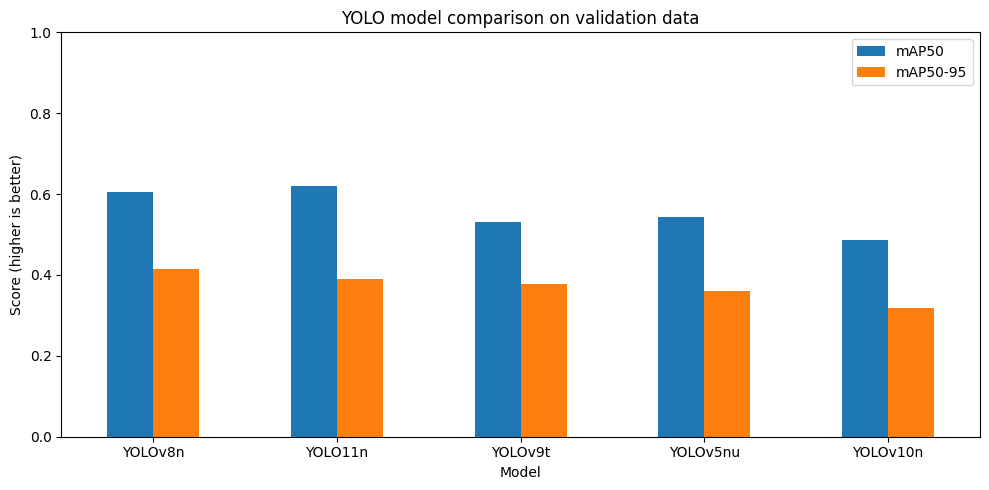

Best model by validation mAP50-95: YOLOv8n
Validation mAP50-95: 0.4139
Trained weights: /content/drive/MyDrive/Shock_Cylinder_Results/experiment_20261009_090436_358249/training/YOLOv8n/weights/best.pt


198

In [ ]:
# 8. Compare validation results and select the best model.
comparison.set_index('Model')[['mAP50', 'mAP50-95']].plot(
    kind='bar', figsize=(10, 5), ylim=(0, 1), rot=0
)
plt.title('YOLO model comparison on validation data')
plt.ylabel('Score (higher is better)')
plt.tight_layout()
plt.savefig(run_folder / 'model_comparison.png', dpi=150)
plt.show()

best_model_name = comparison.iloc[0]['Model']
best_weights = comparison.iloc[0]['Weights']
print('Best model by validation mAP50-95:', best_model_name)
print('Validation mAP50-95:', round(comparison.iloc[0]['mAP50-95'], 4))
print('Trained weights:', best_weights)
(run_folder / 'selected_model.json').write_text(json.dumps({
    'model': best_model_name, 'weights': best_weights,
    'selection_metric': 'validation mAP50-95'
}, indent=2))

## 9. Model testing

Evaluate the selected checkpoint on the separate test split. Ultralytics uses `model.val(split='test')` for labelled test evaluation. Keep the model and evaluation settings fixed at this point. The next cell saves overall and per-class metrics; it does not retrain the model.

In [ ]:
from ultralytics import YOLO
import pandas as pd

# 1. Get the best model directly from the comparison table in memory
best_model_name = comparison.iloc[0]['Model']
best_weights = comparison.iloc[0]['Weights']

print(f"Testing the best validation model: {best_model_name}")

# 2. Run the test evaluation
best_model = YOLO(best_weights)
test_metrics = best_model.val(
    data=data_path,
    split='test',
    imgsz=640,
    batch=8,
    device=0,
    conf=0.001,
    iou=0.7,
    workers=2,
    plots=True,
    project=str(run_folder / 'testing'),
    name=best_model_name
)

# 3. Create and show simplified results
test_summary = pd.DataFrame([{
    'Model': best_model_name,
    'Precision': float(test_metrics.box.mp),
    'Recall': float(test_metrics.box.mr),
    'mAP50': float(test_metrics.box.map50),
    'mAP50-95': float(test_metrics.box.map)
}])
display(test_summary.round(4))

Testing the best validation model: YOLOv8n
Ultralytics 8.3.221 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.1 ms, read: 67.9±11.5 MB/s, size: 66.1 KB)
val: Scanning /content/drive/MyDrive/Scrap Hazdetection.v3-v5.yolov9/test/labels.cache... 16 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 16/16 30.1Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.8it/s 0.7s
                   all         16         26      0.464       0.68      0.445      0.275
              Cylinder          9         19      0.456      0.789      0.534      0.364
        Shock Absorber          6          7      0.471      0.571      0.356      0.187
Speed: 5.9ms preprocess, 7.6ms inference, 0.0ms loss, 4.9ms postprocess per image
Results saved to /content/drive/MyDrive/Shock_Cylinder_Results/experimen

,Model,Precision,Recall,mAP50,mAP50-95
0,YOLOv8n,0.4637,0.6805,0.4451,0.2753


THE BACKGROUND CLASS IN OBJECT DETECTION (YOLO): WHY, WHAT, AND HOW
=========================================================================

1. WHY IS IT USED?
- Traditional classification models assume every image contains exactly one
  valid object.
- Object detection models (like YOLO) must process raw scenes that contain vast
  empty spaces, unrelated textures, or complex backgrounds.
- The "Background" class acts as a catch-all safety category to handle elements
  associated with localization failures (missing bounding boxes) or precision
  failures (false boxes on empty areas).

2. WHAT DOES IT REPRESENT?
- BACKGROUND AS A ROW (Bottom Row of Confusion Matrix):
  Represents False Positives. The model predicted a box containing a class
  (e.g., Cylinder) but the underlying ground truth was actually nothing
  but empty background space.
- BACKGROUND AS A COLUMN (Right Column of Confusion Matrix):
  Represents False Negatives. A real object exists in the ground-truth annotations,
  but the model missed it completely, identifying it as "background" space.

3. HOW DOES IT HELP YOU IMPROVE YOUR MODEL?
- If Background Row values are high:
  Your model is too sensitive and hallucinates objects in empty spots.
  * Solution: Add negative background images (images with no target objects)
    to training, or increase the confidence threshold (`conf`).
- If Background Column values are high:
  Your model is blind to real objects.
  * Solution: Increase your image training size (`imgsz`), add more labeled
    training data, or reduce the confidence threshold.

results.png


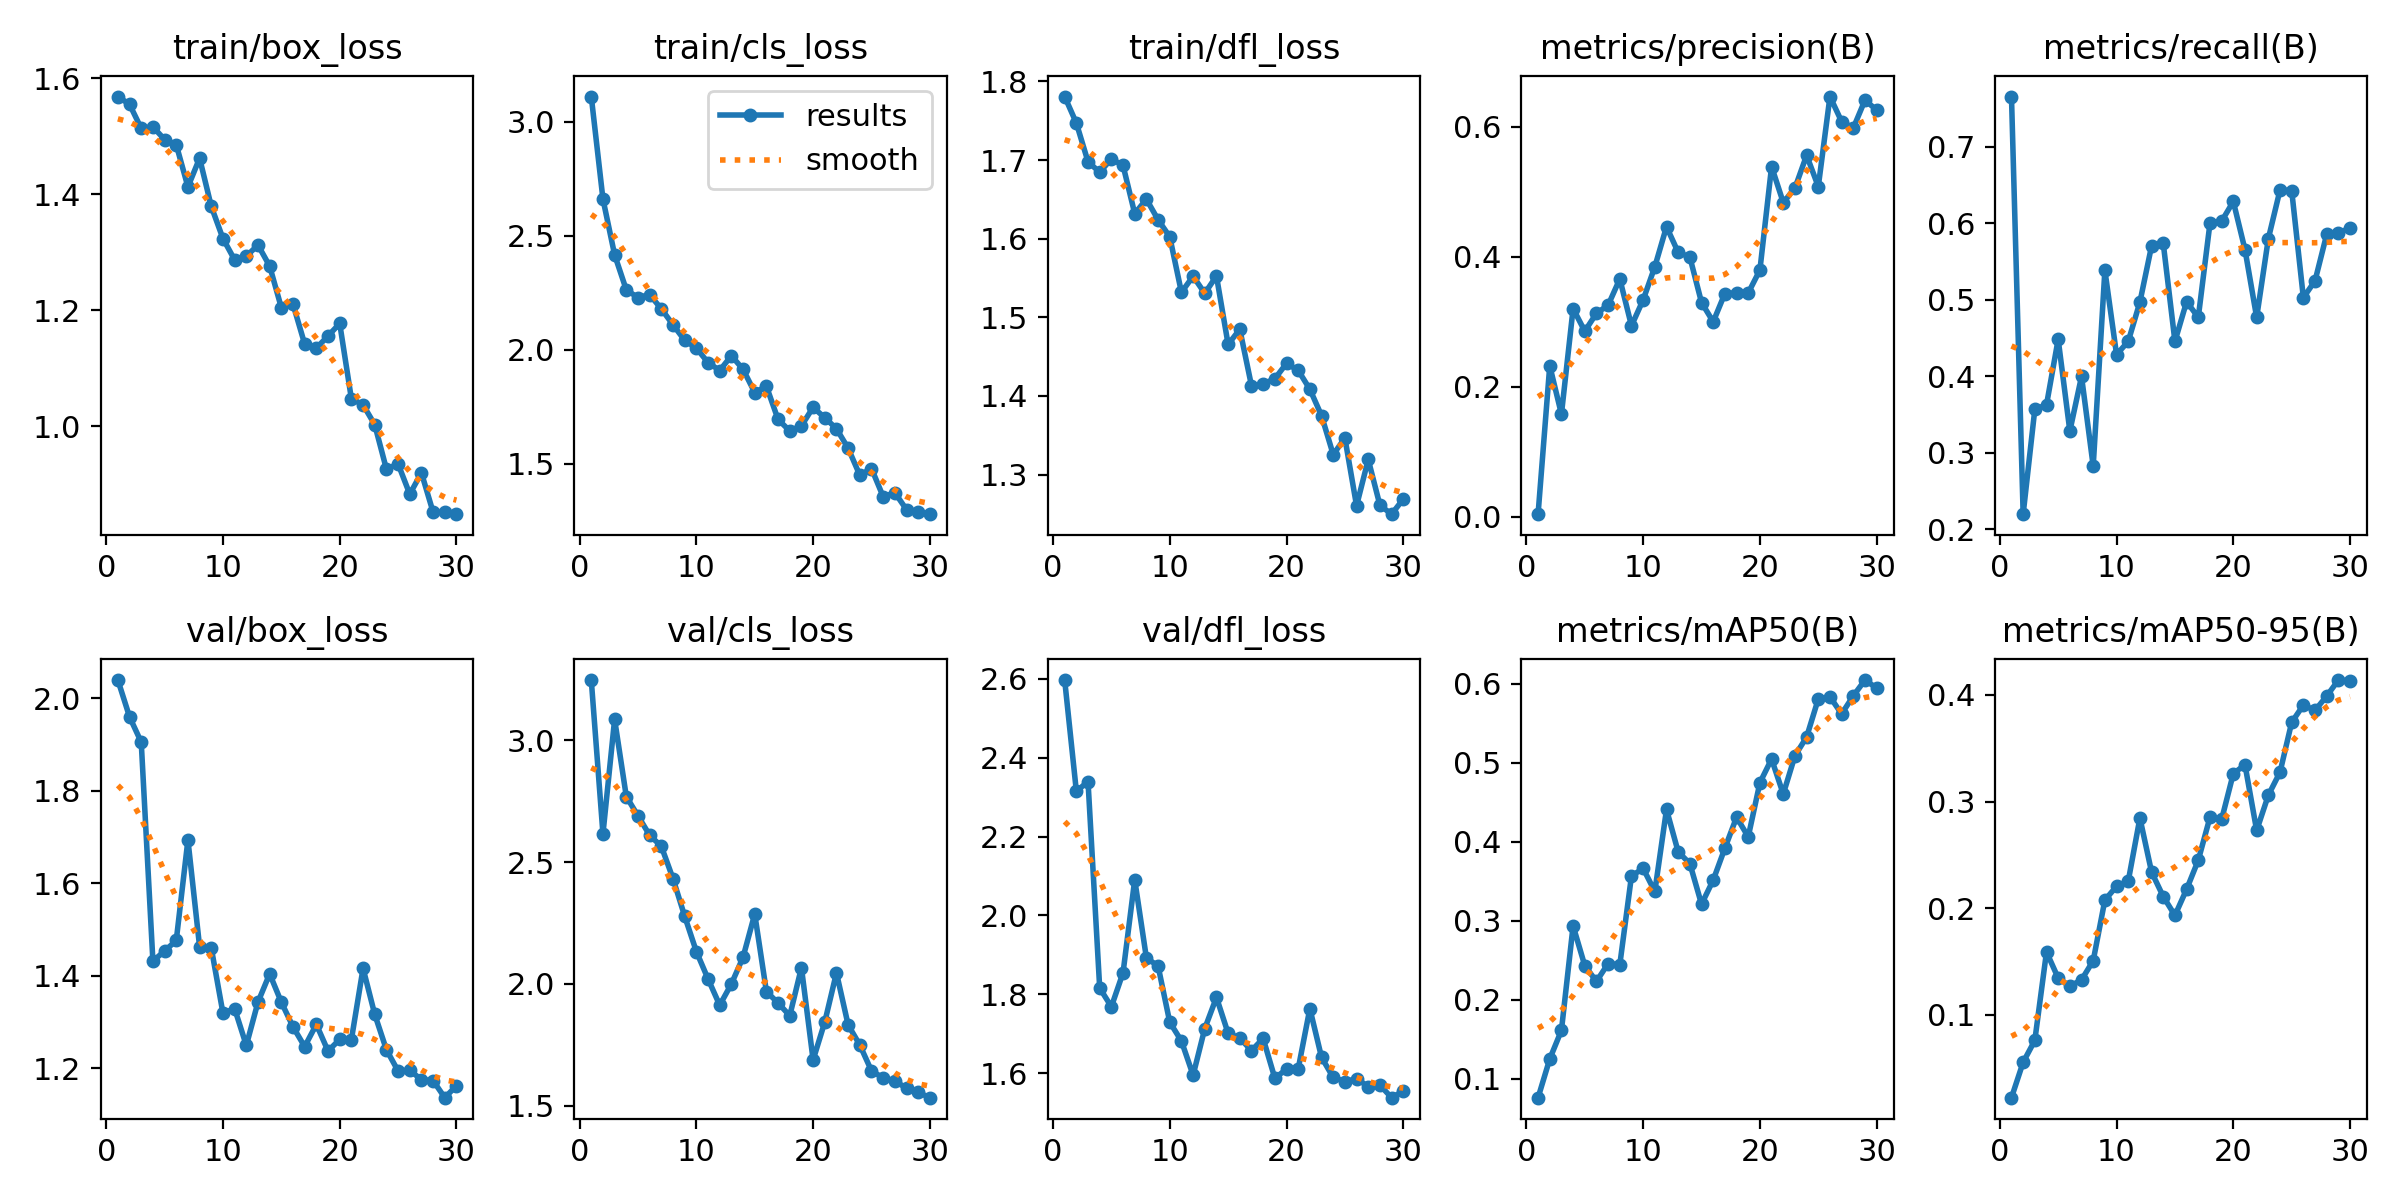

confusion_matrix.png


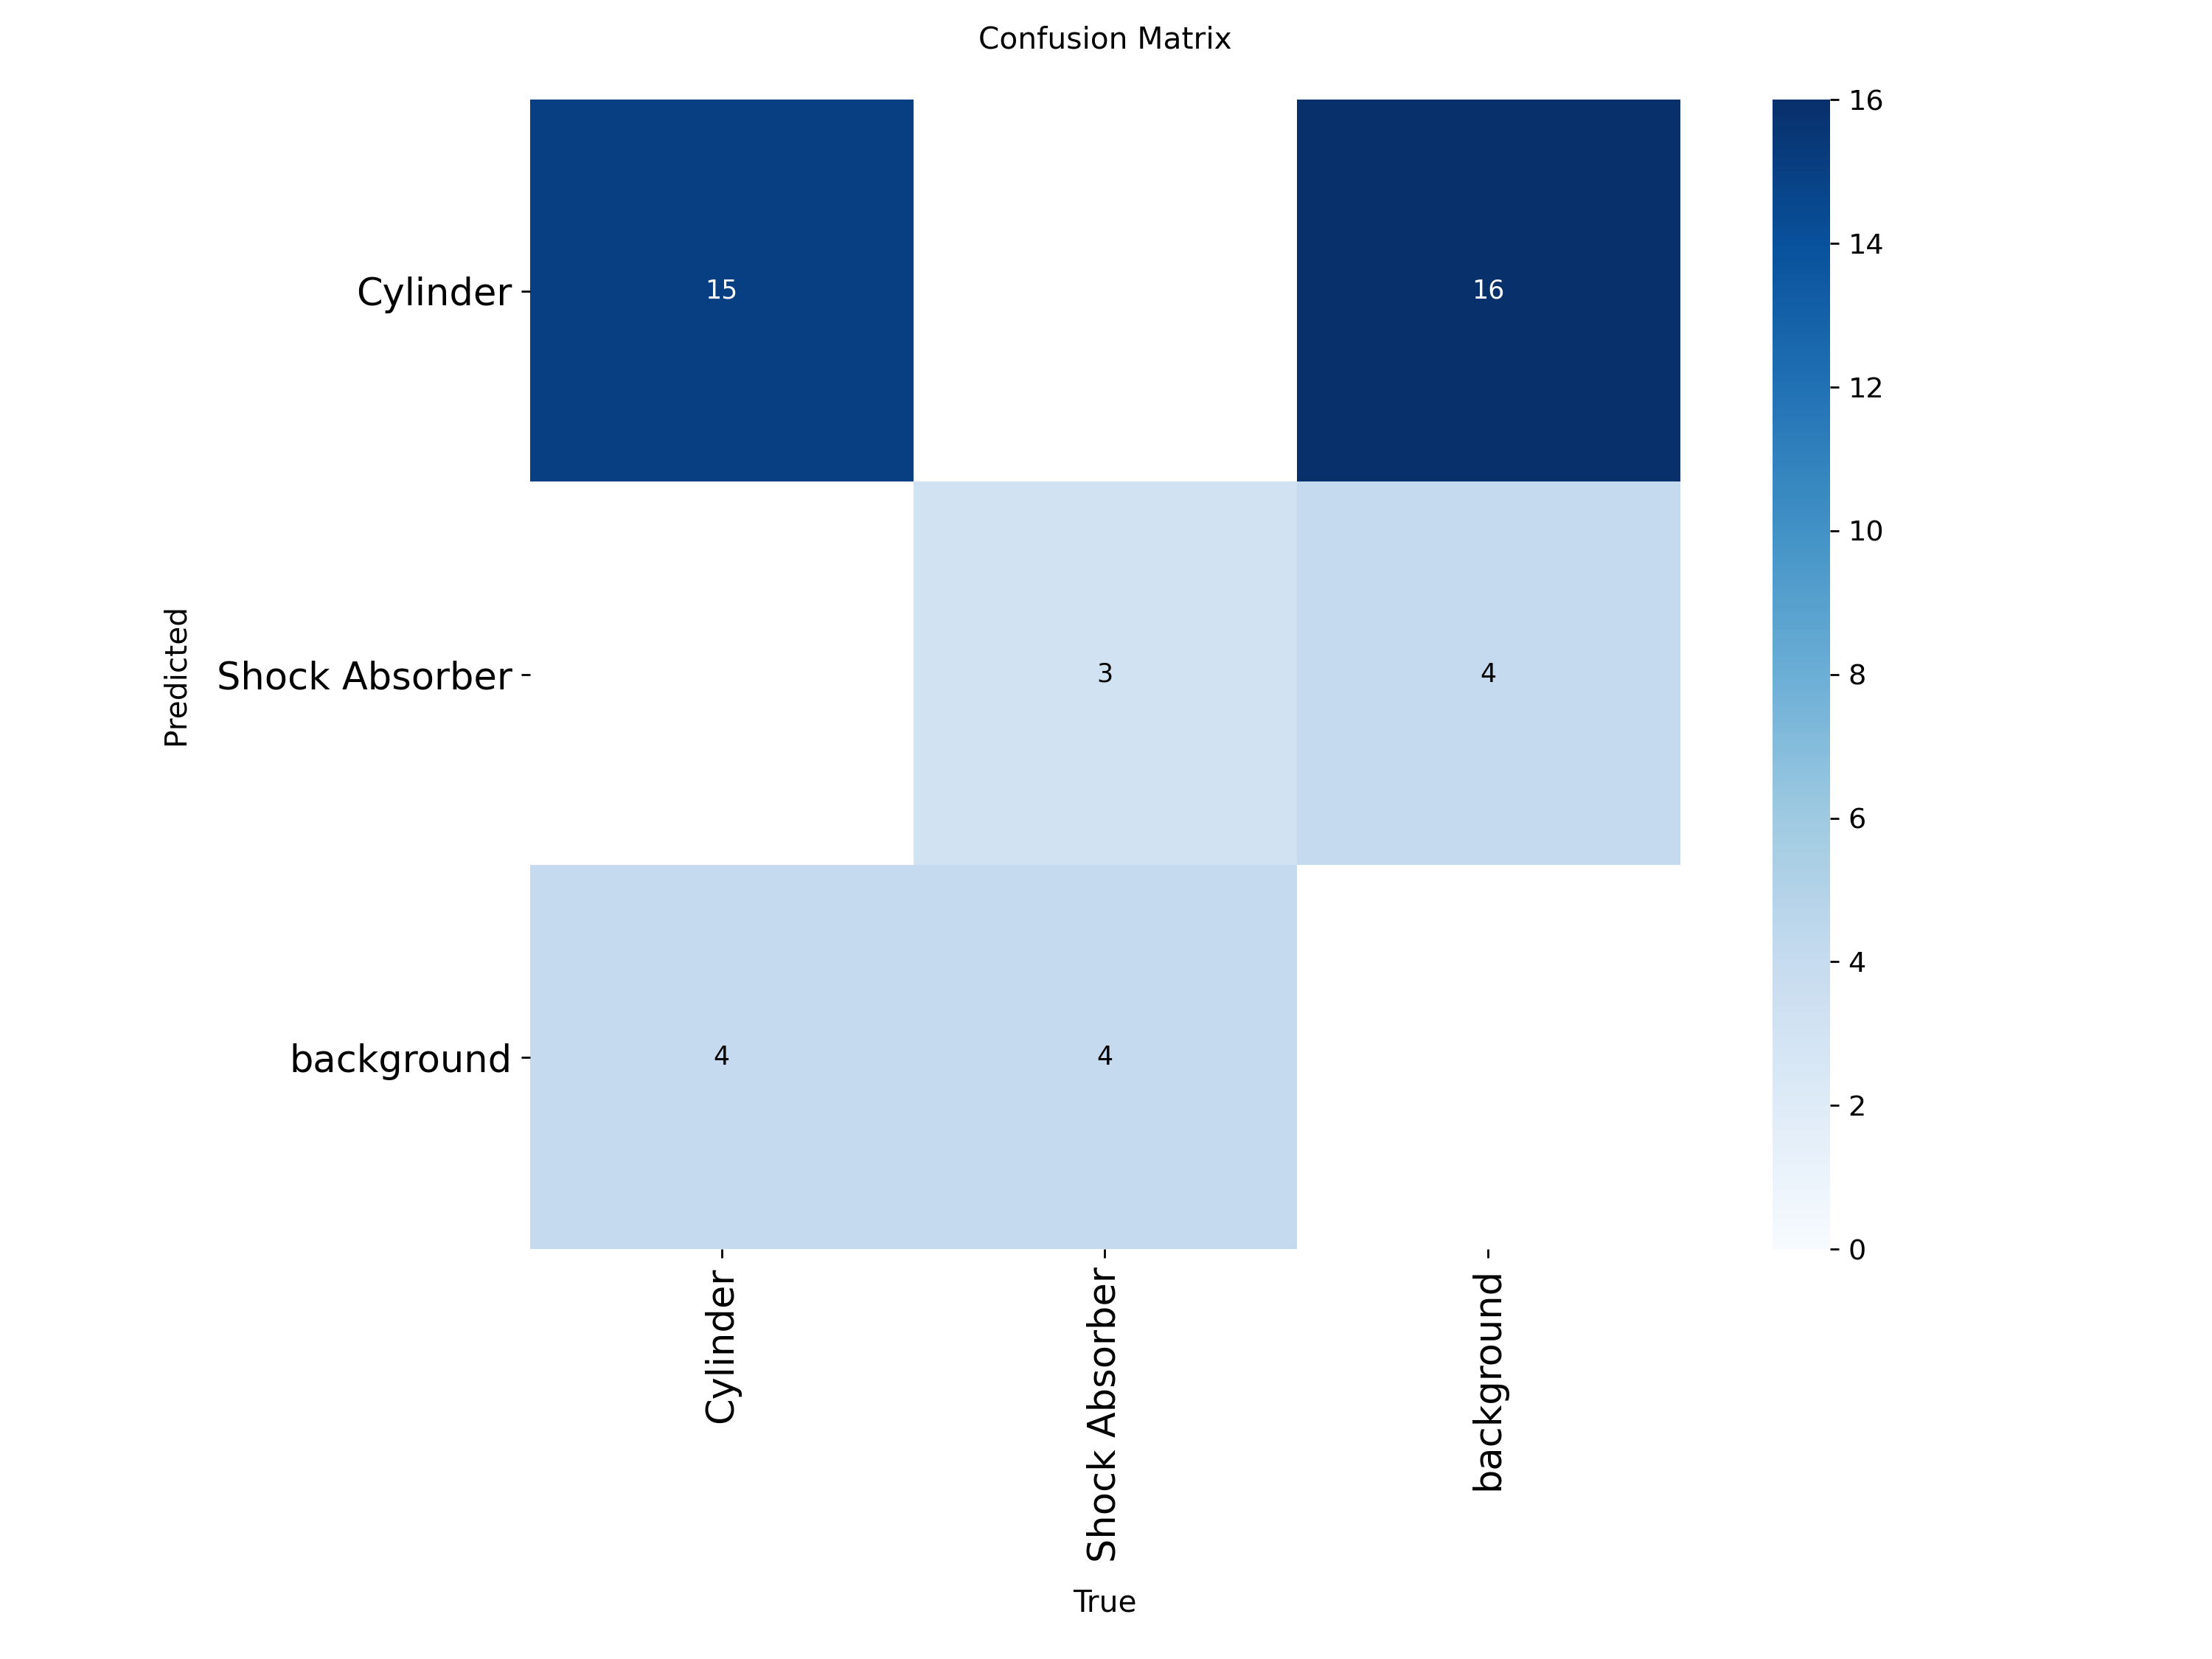

confusion_matrix_normalized.png


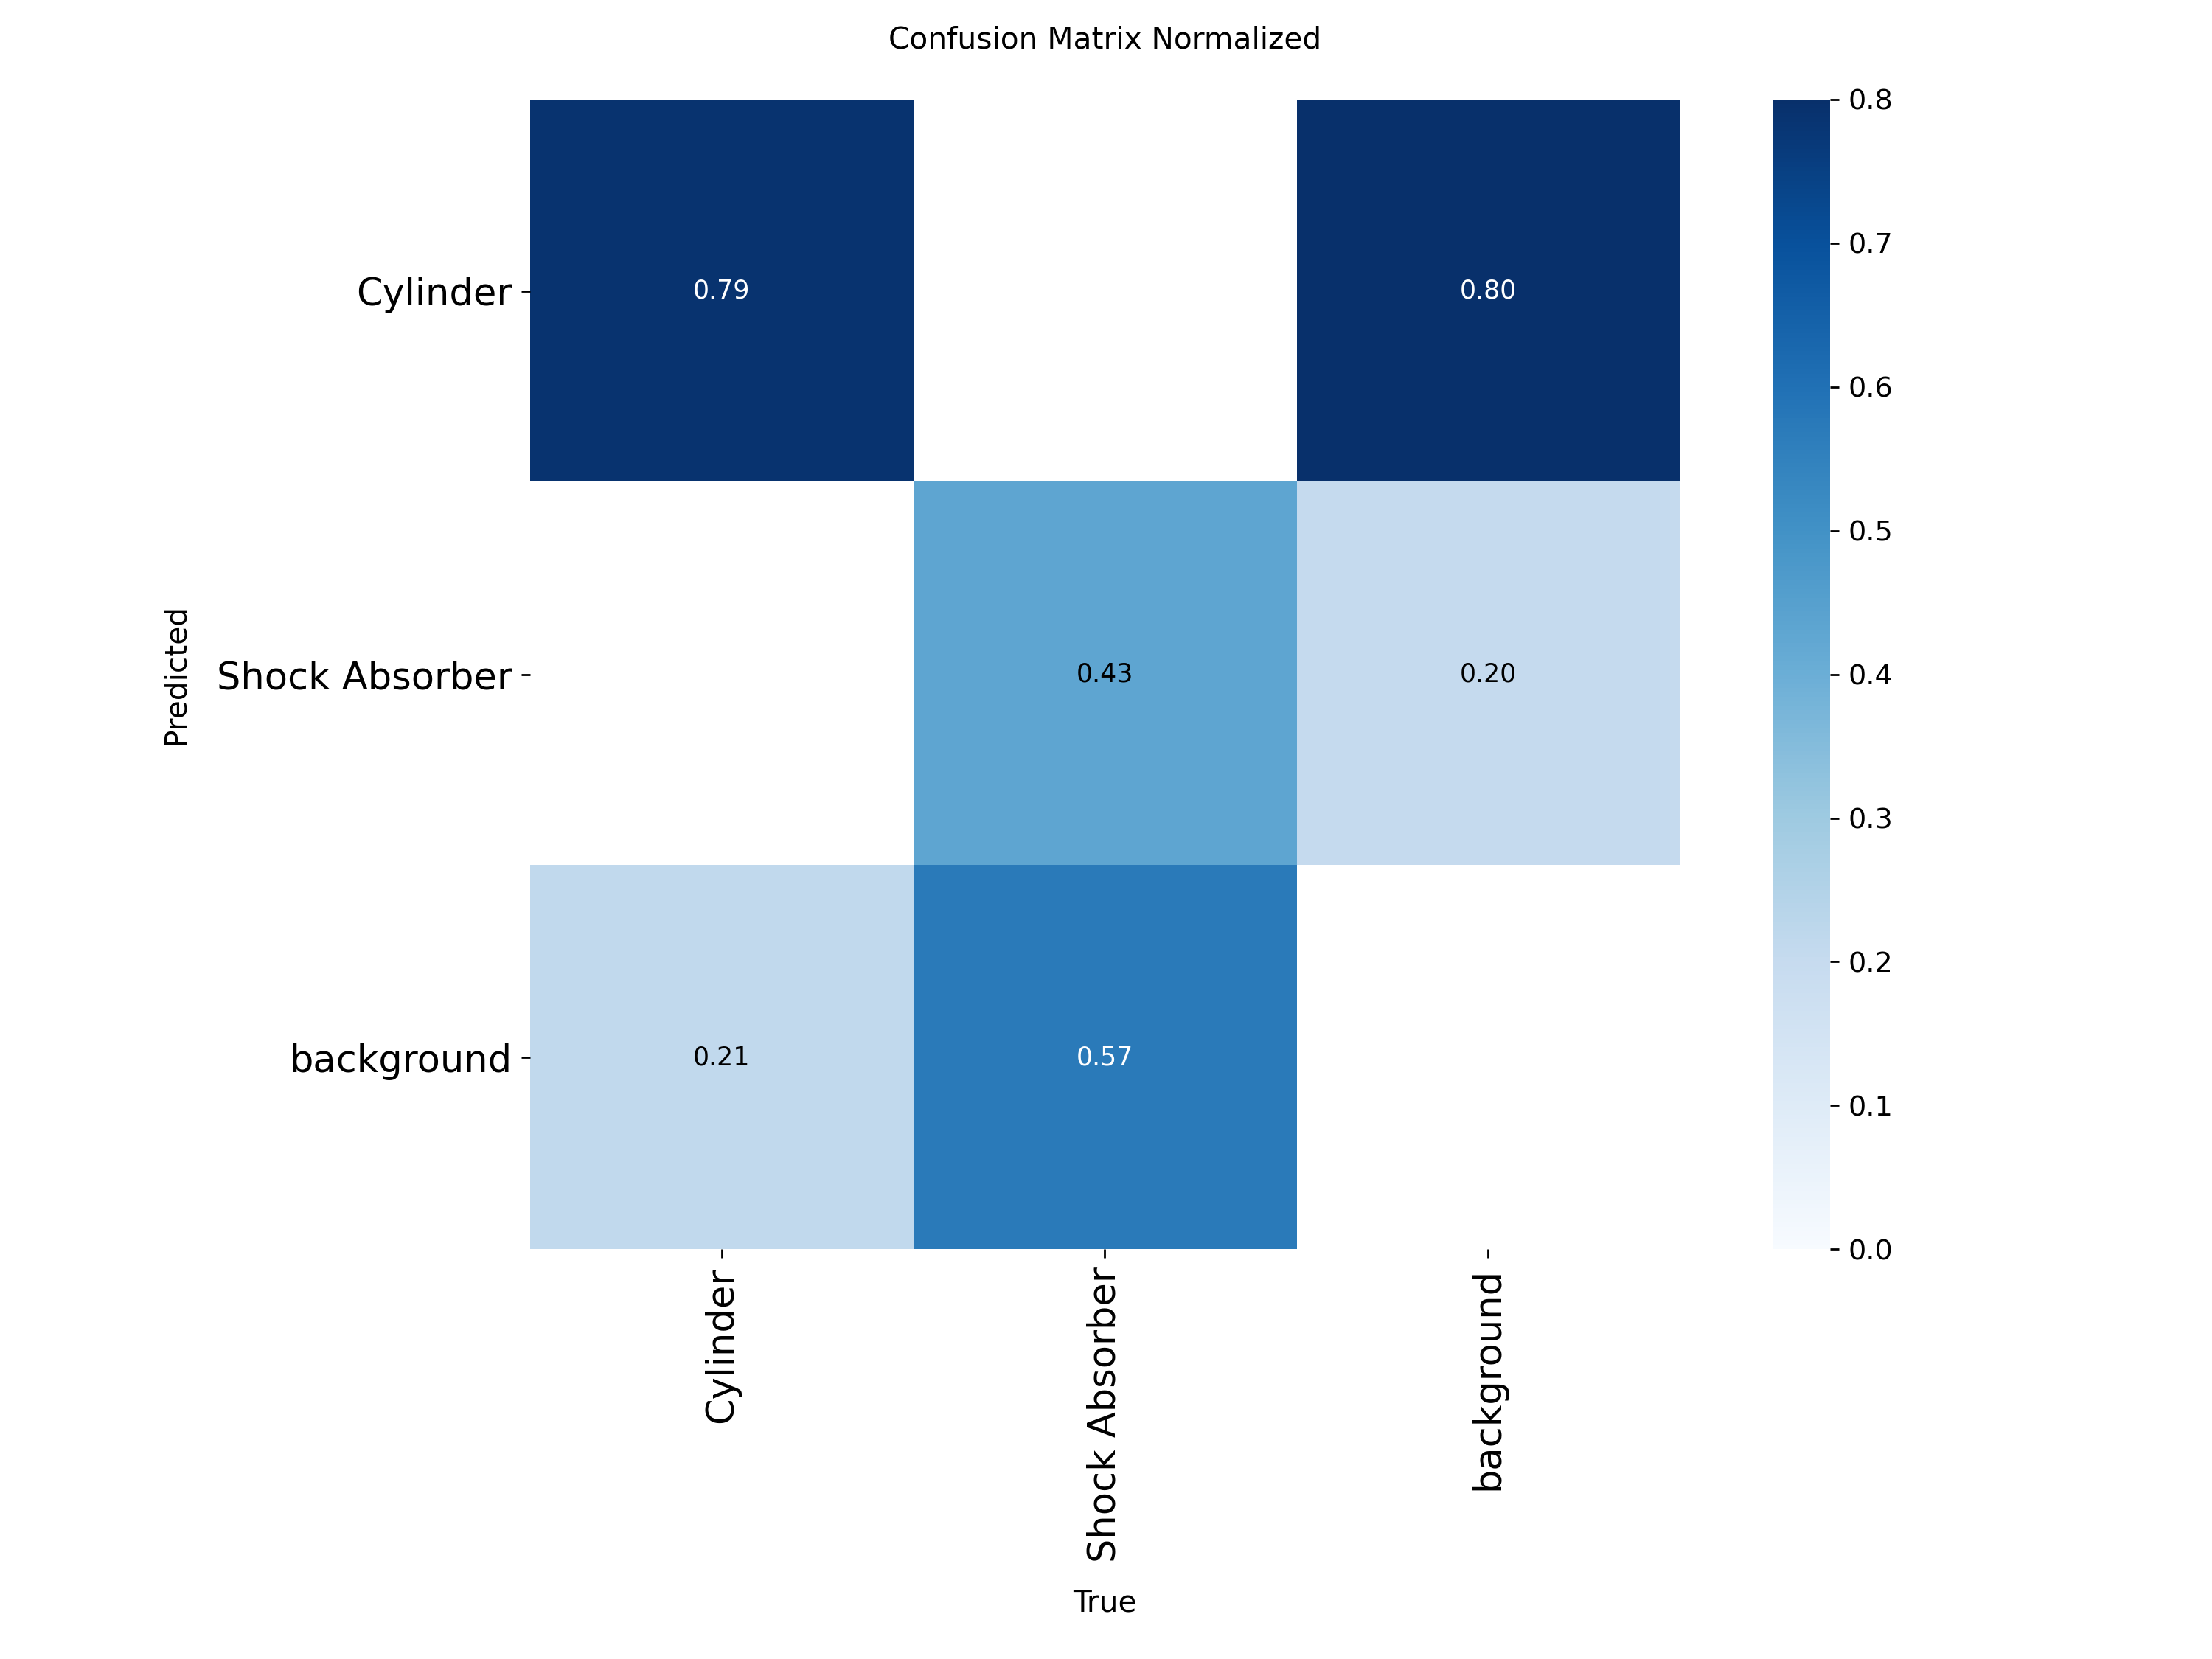

In [ ]:
# 10. Display the selected model's training curves and test confusion matrix.
training_folder = Path(best_weights).parent.parent
testing_folder = Path(test_metrics.save_dir)


for plot_path in [training_folder / 'results.png',
                  testing_folder / 'confusion_matrix.png',
                  testing_folder / 'confusion_matrix_normalized.png']:
    if plot_path.is_file():
        print(plot_path.name)
        with Image.open(plot_path) as plot:
            display(plot.copy())
    else:
        print('Plot not available:', plot_path.name)



0: 640x640 1 Cylinder, 7.4ms
1: 640x640 1 Shock Absorber, 7.4ms
2: 640x640 2 Shock Absorbers, 7.4ms
3: 640x640 2 Shock Absorbers, 7.4ms
4: 640x640 (no detections), 7.4ms
5: 640x640 (no detections), 7.4ms
Speed: 2.7ms preprocess, 7.4ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/drive/MyDrive/Shock_Cylinder_Results/experiment_20261009_090436_358249/predictions/YOLOv8n
Screenshot-2025-02-09-215322_png_png.rf.df14f73f179c79808137fdfe723d47f9.jpg


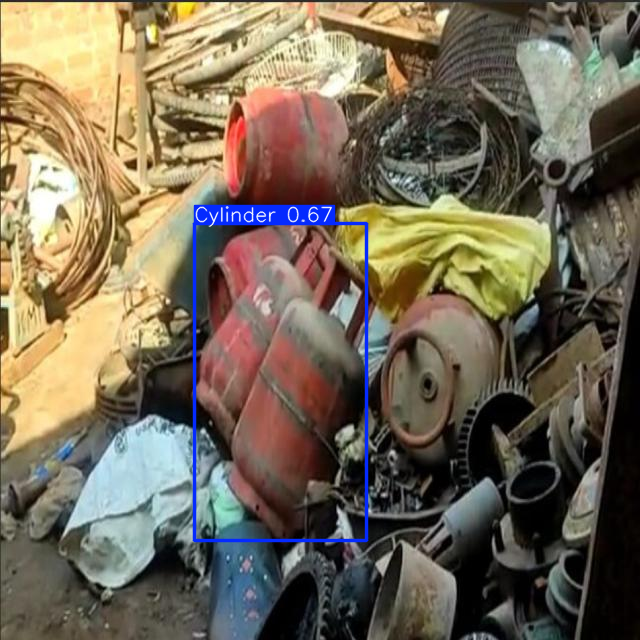

Screenshot-2025-02-16-221152_png_png.rf.d182b98eeabb7805499b64c956e3190a.jpg


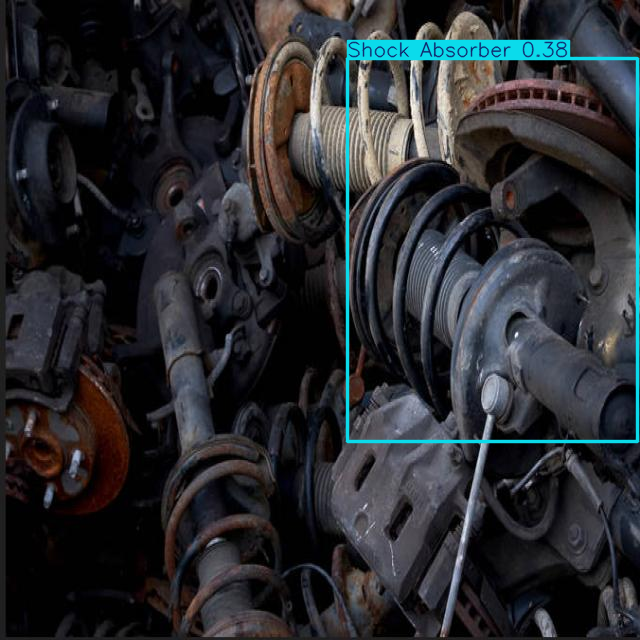

Screenshot-2025-02-16-225021_png_png.rf.9c7e463bf80c948fdb5a5774ae5760af.jpg


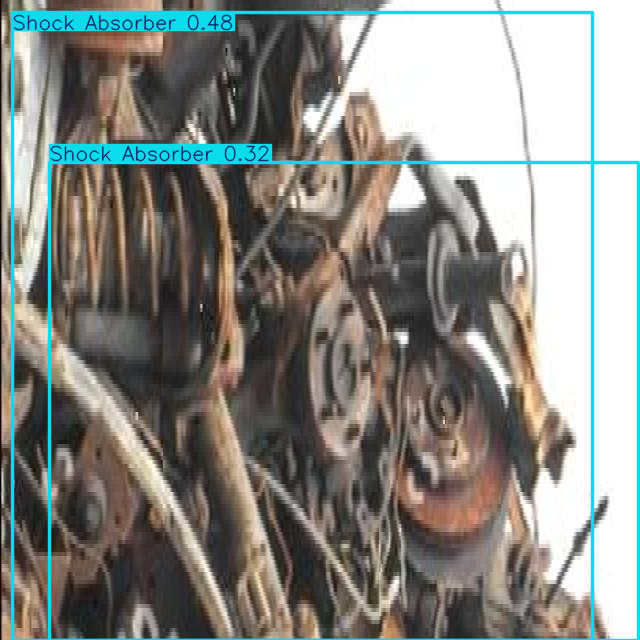

Screenshot-2025-02-16-225122_png_png.rf.88bac42628cf8a4a015fc592db9dc23a.jpg


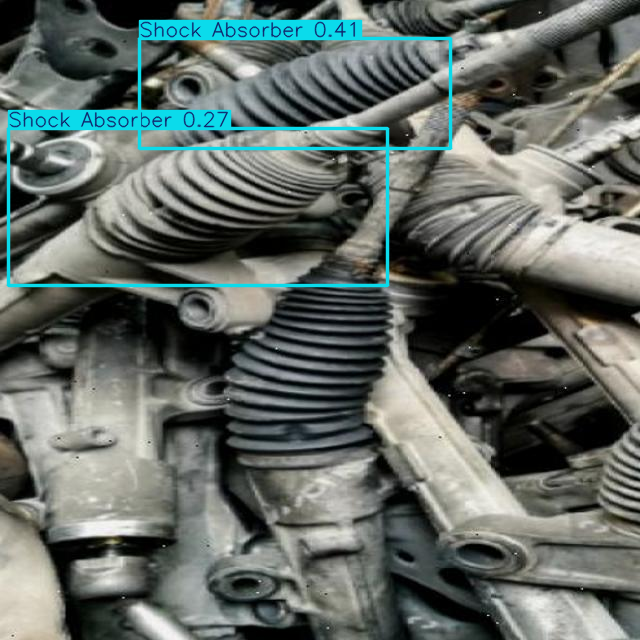

Screenshot-2025-02-16-225720_png_png.rf.7f8b38590bd17027471521ed7299ba42.jpg


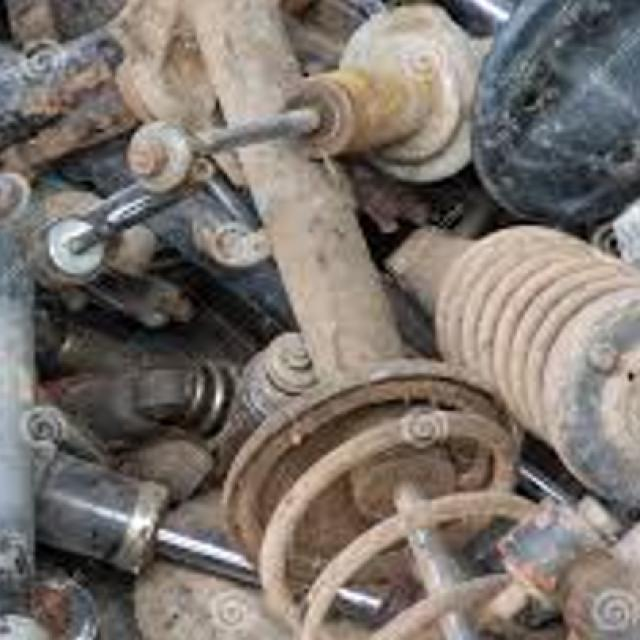

Screenshot-2025-02-16-230523_png_png.rf.f51f8401e08a71d9da38b4b2a43952ae.jpg


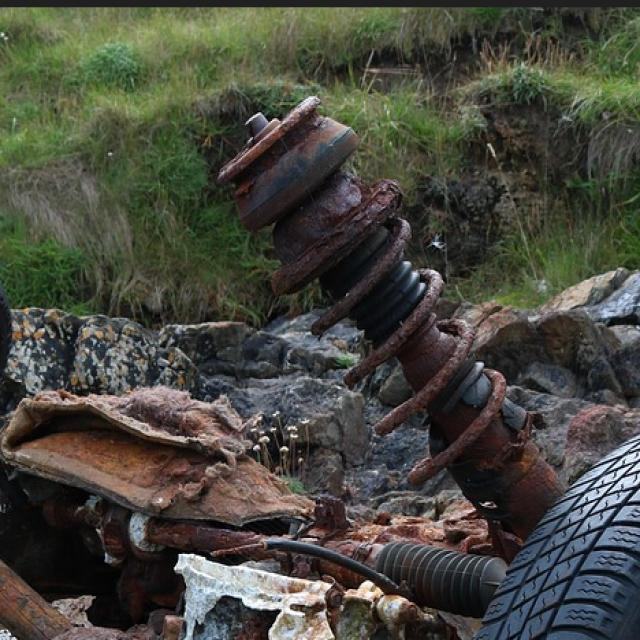

In [ ]:
# 11. Show bounding-box predictions on up to six test images.
# This 0.25 confidence threshold is for visualization, not the AP calculation.
test_images = sorted(p for p in (dataset_folder / 'test' / 'images').iterdir()
                     if p.suffix.lower() in image_types)[:6]
if not test_images:
    raise ValueError('No test images found.')

predictions = best_model.predict(
    source=[str(p) for p in test_images],
    imgsz=IMAGE_SIZE,
    conf=0.25,
    iou=0.7,
    device=DEVICE,
    save=True,
    project=str(run_folder / 'predictions'),
    name=best_model_name
)
for result in predictions:
    print(Path(result.path).name)
    display(Image.fromarray(result.plot()[..., ::-1]))  # Convert BGR to RGB.

### Where to find the results

Open **Google Drive → MyDrive → Shock_Cylinder_Results → experiment_…**.
The folder contains model checkpoints, the validation comparison CSV and chart, test scores, and prediction images. The full path to the selected model is printed in Step 8.

If Colab runs out of GPU memory, lower `BATCH_SIZE` in Step 5 (for example, from 8 to 4) and rerun all models with the same new setting for a consistent comparison.

API references: [Ultralytics training](https://docs.ultralytics.com/modes/train/) and [Ultralytics validation/testing](https://docs.ultralytics.com/modes/val/). The notebook keeps your existing `ultralytics==8.3.221` installation pin.